# 2. Datos: ETL, EDA y auditoría de fuga

Este capítulo resume el ETL y el EDA con las tablas que importan para el modelo original, declara los datos y documenta
la auditoría de fuga de información. El análisis completo está en los capítulos de las entregas anteriores
([Data](../Entrega3/notebook/01_datos), [EDA de la Entrega 1](../Entrega1/eda_bancario)) y, de forma interactiva, en la
sección **EDA** del [dashboard](https://fuga-de-clientes-dash.onrender.com/eda). Todo lo que sigue se calcula solo con
la partición de entrenamiento.

In [1]:
# Preparación: acceso a los resultados versionados y a las funciones que generan las
# tablas y figuras del informe.
import sys
sys.path.insert(0, '../ModeloOriginal')
from src import informe as inf

## 2.1. El conjunto y su declaración

COFINFAD {cite}`munoz2025` describe a los clientes de una fintech colombiana y el detalle de sus transacciones de 2023.
La {ref}`Tabla 2.1 <tab-declaracion>` es la declaración de los datos: de dónde vienen, con qué licencia se
distribuyen, cómo están compuestos y qué sesgos se conocen. El punto que más condiciona la lectura de este libro es el
de la naturaleza: los datos son **sintéticos**, de modo que cada conclusión describe las reglas con que se generaron y
no a clientes reales.

(tab-declaracion)=
**Tabla 2.1.** Declaración de los datos: procedencia, licencia, composición, sesgos conocidos y usos.

In [2]:
# Tabla 2.1. Cifras calculadas con los resúmenes del entrenamiento
# (Dashboard/datos/eda); la procedencia y la licencia son las de la publicación del
# conjunto en Mendeley Data.
inf.tabla('tabla_declaracion')

| Aspecto | Declaración |
| :--- | :--- |
| Conjunto | COFINFAD: *Colombian Fintech Financial Analytics Dataset* |
| Procedencia | Muñoz Guerrero, Ceballos y Trejos Rojas; publicado en Mendeley Data, versión 1, 2025; DOI [10.17632/mhb4zn3258.1](https://doi.org/10.17632/mhb4zn3258.1) |
| Licencia | CC BY 4.0: se puede usar y redistribuir citando a los autores |
| Composición | 48.723 clientes, uno por fila, con 54 columnas, y 3.159.157 transacciones de 2023 en una tabla aparte |
| Naturaleza | **Sintético**, generado con reglas. Sus huellas: la edad solo toma 6 valores (29, 30, 44, 45, 59 y 60); el puntaje baja en escalones casi idénticos con el número de productos activos (r de Pearson = −0,876); y las 12 variables derivadas de las transacciones casi no se asocian con el puntaje (ρ de Spearman de a lo sumo 0,018 en valor absoluto) |
| Objetivo | `churn_probability`, un puntaje de propensión entre 0,114 y 0,501 en entrenamiento: nunca vale 0 ni 1 y no es una fuga observada |
| Sesgos conocidos | Las cohortes de edad tienen tasas de riesgo alto muy distintas (del 8,7 % al 45,2 %); el archivo está ordenado por cohortes, y por eso la partición es aleatoria y no por posición; el uso del cupo falta exactamente cuando el cliente no tiene tarjeta de crédito (37,4 % de los clientes de entrenamiento): es un «no aplica», no un dato perdido, y se imputa con 0; las columnas de texto (`complaint_topics`, `feature_requests`) tienen entre el 33 % y el 50 % de faltantes y se excluyen |
| Usos adecuados | Enseñar y comparar métodos de aprendizaje supervisado con un protocolo reproducible; estudiar fugas de información, calibración y modelos legibles |
| Usos no recomendados | Sacar conclusiones sobre clientes reales, estimar tasas reales de abandono (el objetivo es un puntaje, no la fuga observada) o tomar decisiones sobre personas |


La declaración completa, con los usos no recomendados y la fuente de cada cifra, está en
[`Dashboard/DATA_STATEMENT.md`](https://github.com/RubenEsg/Prediccion-de-fuga-de-clientes-en-fintech/blob/main/Dashboard/DATA_STATEMENT.md).

## 2.2. ETL

El flujo está en `ModeloOriginal/src/datos.py` y la {ref}`Tabla 2.2 <tab-etl>` resume qué deja cada paso. La partición
va antes que todo lo demás: la evidencia para eliminar columnas, el umbral de la etiqueta y la fecha de corte de la
recencia salen solo de los clientes de entrenamiento (38.978; los de prueba son 9.745).

(tab-etl)=
**Tabla 2.2.** Pasos del ETL y resultado de cada uno.

In [3]:
# Tabla 2.2. Lee Dashboard/datos/eda/etl.json, que resume la carga, la auditoría de
# las transacciones y las columnas.
inf.tabla('tabla_etl')

| Paso | Resultado |
| :--- | :--- |
| 1. Carga | 48.723 clientes con 54 columnas; el detalle de transacciones, en una tabla aparte |
| 2. Auditoría de las transacciones | 102 filas exactamente duplicadas, que se eliminan (quedan 3.159.055); 0 montos no positivos, 0 fechas nulas, 0 transacciones sin cliente y 0 clientes sin transacciones |
| 3. Partición | Entrenamiento y prueba (80/20, semilla 42), antes de mirar el objetivo y antes de derivar variables |
| 4. Variables derivadas | 12, del detalle de transacciones y sin usar el objetivo: `n_tx`, `monto_total`, `monto_medio`, `monto_mediano`, `recencia_dias`, `dias_activo`, `volatilidad_monto`, `meses_activos`, `prop_Deposit`, `prop_Payment`, `prop_Transfer`, `prop_Withdrawal` |
| 5. Columnas eliminadas | 17: `customer_id`, `active_products`, `customer_lifetime_value`, `clv_segment`, `average_transaction_value`, `total_transaction_volume`, `avg_daily_transactions`, `monthly_transaction_count`, `first_transaction_date`, `last_transaction_date`, `nps_score`, `occupation`, `complaint_topics`, `feature_requests`, `last_survey_date`, `first_tx`, `last_tx` |
| 6. Predictores | 48: 32 numéricos, 7 booleanos y 9 categóricos |


Las 17 columnas eliminadas son el identificador, la variable que genera el objetivo (`active_products`), un segundo
objetivo (el valor del cliente y su segmento), cuatro duplicados de otras columnas, una variable colineal con la
satisfacción (`nps_score`), la ocupación y cinco fechas, que no tienen señal, y dos columnas de texto libre con muchos
faltantes. La etiqueta «riesgo
alto» es el cuarto superior del puntaje, con el umbral (0,3927) estimado solo en entrenamiento. El preprocesamiento
(estandarizar las numéricas y codificar las categóricas) vive dentro de la tubería (*pipeline*) de cada modelo, de modo
que se ajusta solo con las filas de entrenamiento de cada pliegue.

Solo tres columnas tienen valores faltantes ({ref}`Tabla 2.3 <tab-faltantes>`). Dos son texto libre y se eliminan. La
tercera, el uso del cupo de la tarjeta, falta exactamente en los clientes sin tarjeta de crédito: es un «no aplica» y se
imputa con 0.

(tab-faltantes)=
**Tabla 2.3.** Columnas con valores faltantes en entrenamiento.

In [4]:
# Tabla 2.3. Lee Dashboard/datos/eda/faltantes.csv (conteo de faltantes por columna
# en la partición de entrenamiento).
inf.tabla('tabla_faltantes')

| Columna | Faltantes | Parte de las filas | ¿Entra al modelo? |
| :--- | ---: | ---: | :--- |
| `complaint_topics` | 19.424 | 49,8 % | No |
| `credit_utilization_ratio` | 14.595 | 37,4 % | Sí |
| `feature_requests` | 12.873 | 33,0 % | No |


## 2.3. EDA: qué se asocia con el puntaje

La {ref}`Tabla 2.4 <tab-asociacion>` ordena las variables por su asociación con el puntaje. Hay una que domina,
`active_products`, y es justo la que no se puede usar. Entre los predictores, la señal está en pocas variables
(frecuencia de uso de la aplicación, edad y satisfacción) y las demás casi no aportan.

(tab-asociacion)=
**Tabla 2.4.** Asociación de las variables con el puntaje de fuga, en entrenamiento.

In [5]:
# Tabla 2.4. Lee Dashboard/datos/eda/asociacion.csv: ρ de Spearman y r de Pearson
# para las numéricas, η² para las categóricas.
inf.tabla('tabla_asociacion')

| Variable | Medida | Asociación con el puntaje | r de Pearson | Uso |
| :--- | :--- | ---: | ---: | :--- |
| `active_products` | ρ de Spearman | −0,844 | −0,876 | Excluida: genera el puntaje |
| `app_logins_frequency` | ρ de Spearman | −0,279 | −0,256 | Predictor |
| `age` | ρ de Spearman | 0,210 | 0,208 | Predictor |
| `satisfaction_score` | ρ de Spearman | −0,190 | −0,186 | Predictor |
| `base_satisfaction` | ρ de Spearman | −0,164 | −0,165 | Predictor |
| `product_satisfaction` | ρ de Spearman | 0,043 | 0,040 | Predictor |
| `income_bracket` | η² | 0,0050 | — | Predictor |
| `location` | η² | 0,0007 | — | Predictor |

Asociación de cada variable con el puntaje, calculada solo en entrenamiento: las 6 numéricas de mayor |ρ| y las dos categóricas de mayor η². De las 39 numéricas que entran al modelo, 29 tienen |ρ| menor que 0,02; ninguna categórica pasa de η² = 0,005.


La edad solo toma seis valores, agrupados en tres cohortes de tamaño casi igual ({ref}`Tabla 2.5 <tab-cohortes>`). El
riesgo alto cambia mucho de una cohorte a otra y no crece con la edad, lo que un modelo lineal no puede representar con
un solo coeficiente y sí un modelo de árboles.

(tab-cohortes)=
**Tabla 2.5.** Puntaje medio y proporción de riesgo alto por cohorte de edad, en entrenamiento.

In [6]:
# Tabla 2.5. Lee Dashboard/datos/eda/cohortes.csv (filas de la partición de
# entrenamiento).
inf.tabla('tabla_cohortes')

| Cohorte de edad | Clientes | Puntaje medio | Riesgo alto |
| :--- | ---: | ---: | ---: |
| 29–30 años | 12.995 | 0,339 | 19,8 % |
| 44–45 años | 12.965 | 0,318 | 8,7 % |
| 59–60 años | 13.018 | 0,373 | 45,2 % |

El riesgo alto va del 8,7 % al 45,2 % según la cohorte, y no crece con la edad: la relación no es monótona.


## 2.4. El hallazgo del EDA que motiva el modelo original

La {ref}`Figura 2.1 <fig-escalera>` muestra el hecho del que parte todo el proyecto.

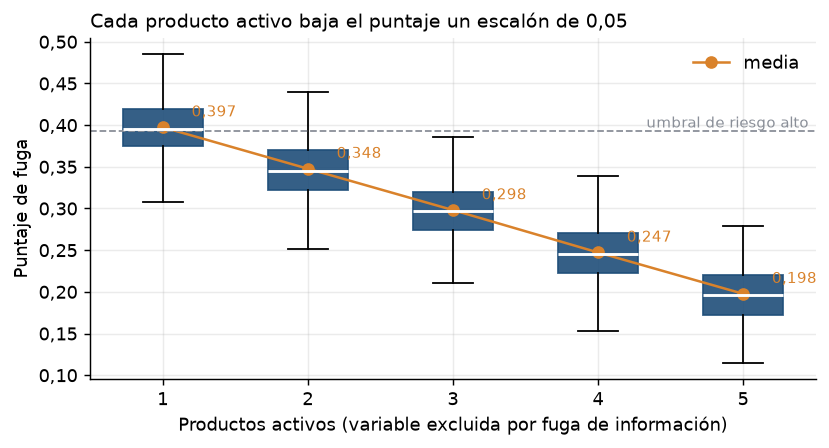

In [7]:
# Figura 2.1. Con la partición de entrenamiento (src/datos.py): diagrama de cajas
# del puntaje por número de productos. active_products se usa aquí solo para
# explicar el EDA; ningún modelo la recibe.
inf.figura('escalera_productos')

`active_products` tiene una correlación de Pearson de −0,88 con el puntaje y se excluye por fuga de información
{cite}`kaufman2012`: el puntaje se construyó con ella. Sin esa variable, los modelos explican cerca del 22 % de la
varianza. El resto no es ruido en el sentido habitual: es el escalón de la variable excluida, que no se puede predecir
con las demás (al intentarlo, el AUC es 0,50).

La {ref}`Figura 2.2 <fig-objetivo>` muestra dónde cae el umbral de la etiqueta.

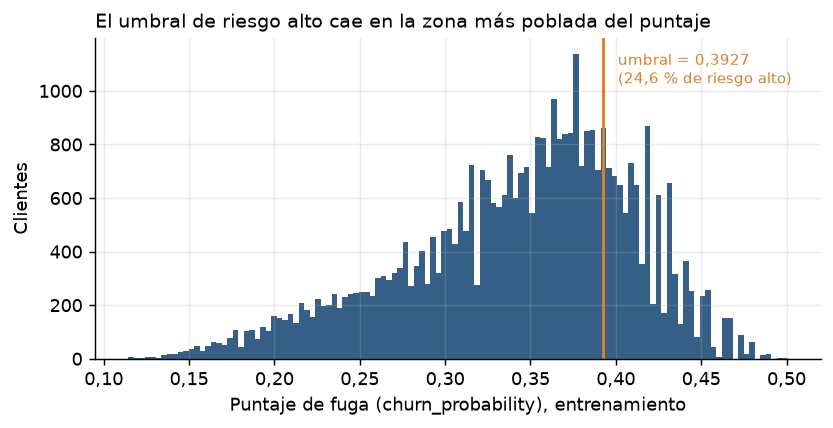

In [8]:
# Figura 2.2. Histograma del puntaje de entrenamiento y umbral de la etiqueta
# (percentil 75, estimado en entrenamiento).
inf.figura('objetivo')

## 2.5. Auditoría de fuga de información

Se hizo antes de ejecutar los experimentos definitivos
([`ModeloOriginal/experiments/01_auditoria_fuga.py`](https://github.com/RubenEsg/Prediccion-de-fuga-de-clientes-en-fintech/blob/main/ModeloOriginal/experiments/01_auditoria_fuga.py)),
con la lista de la guía (§3). La fuga de información es una de las causas más frecuentes de resultados que no se
reproducen en aprendizaje automático {cite}`kapoor2023`; por eso la auditoría recorre todos los tipos de la lista y no
solo el que señaló el docente.

**La fuga señalada por el docente.** En el Entregable 3 la recencia se medía contra la última fecha de todo el detalle,
que incluye las transacciones de los clientes de prueba. Ahora la fecha de corte sale solo de entrenamiento. La
{ref}`Tabla 2.6 <tab-fuga>` compara los dos procedimientos.

(tab-fuga)=
**Tabla 2.6.** Auditoría de la recencia: el flujo del Entregable 3 frente al flujo corregido.

In [9]:
# Tabla 2.6. Lee resultados/auditoria_fuga.json, que escribe
# experiments/01_auditoria_fuga.py al comparar los dos flujos.
inf.tabla('tabla_fuga')

| Comprobación | Resultado | Detalle |
| :--- | :--- | :--- |
| La partición es la del Entregable 3 | Sí | 38.978 de entrenamiento y 9.745 de prueba; 0 clientes en las dos |
| Fecha de corte con todo el detalle (Entregable 3) | 2023-12-29 | Incluía a los clientes de prueba |
| Fecha de corte solo con entrenamiento (corrección) | 2023-12-29 | La misma: hay 3.880 clientes de entrenamiento con una transacción ese día |
| Celdas de recencia que cambian | 0 | Clientes con la última transacción posterior al corte: 0 |
| Predictores idénticos antes y después | Sí | Huella de entrenamiento `7afab737a66ee44a`; de prueba `78d2cf333bf8df15` |
| Pliegues de la validación anidada con otra fecha de corte | 0 de 120 | Tres repeticiones, externos e internos, las dos tareas |
| Diferencia máxima de la recencia estandarizada al mover el corte entre −30 y +365 días | 1,8e-15 | La fecha de corte se cancela al estandarizar |


La corrección no cambia ningún dato, y hay una razón de fondo por la que tampoco podría cambiar un resultado. La
recencia es $\text{corte} - u$, con $u$ la fecha de la última transacción del cliente. Todos los modelos la estandarizan
dentro de la tubería con la media y la desviación de las filas de entrenamiento:

$$
z = \frac{(\text{corte} - u) - (\text{corte} - \bar u)}{s_u} = -\frac{u - \bar u}{s_u},
$$ (eq-recencia)

que no contiene la fecha de corte. La fuga era real como procedimiento (un parámetro calculado con filas de prueba) y
por eso se corrige; su efecto numérico era nulo.

**El resto de la lista.** La {ref}`Tabla 2.7 <tab-lista-fuga>` recorre los demás tipos de fuga que enumera la guía.

(tab-lista-fuga)=
**Tabla 2.7.** Comprobaciones de fuga de información y su resultado.

| Tipo de fuga | Qué se comprobó | Resultado |
|---|---|---|
| Preprocesamiento ajustado sobre todo el conjunto | El escalado y la codificación están dentro de cada tubería | Se ajustan solo con las filas de entrenamiento de cada pliegue externo e interno |
| Variables que codifican la respuesta | Correlación de cada candidata con el objetivo, solo en entrenamiento | `active_products` (r = −0,88) y el valor del cliente, excluidas |
| Duplicados entre particiones | Clientes repetidos y cruce de identificadores | Ningún cliente está en las dos particiones |
| Umbral de la etiqueta | Con qué filas se estima | Solo con entrenamiento; dentro de la validación es una constante |
| Mezcla temporal | Estructura temporal del conjunto | Corte transversal de 2023 con partición aleatoria por cliente; el único parámetro temporal común era la fecha de corte, ya corregida |
| Puntaje continuo en el modelo original | Qué filas lo aportan | Entra como parámetro de ajuste y scikit-learn lo recorta a las filas de entrenamiento de cada pliegue (`test_validacion_anidada_recorta_el_puntaje_por_pliegue`) |
| Repartos internos del modelo original | Dónde se hacen | Dentro de las filas de entrenamiento que recibe: ajuste, validación y calibración |

**Sobre `active_products`.** Ningún modelo la recibe, ni el original ni los benchmarks. Lo que el modelo original
aprende es que el residuo del puntaje tiene niveles, y eso se ve en el propio puntaje de entrenamiento
({ref}`Figura 5.1 <fig-escalones>`). La variable solo se usa fuera de los modelos, para explicar y para diagnosticar:

- en el EDA, para mostrar por qué aparecen los niveles ({ref}`Figura 2.1 <fig-escalera>`);
- en la sección 5.1, para medir el error del índice de cada modelo una vez descontado el escalón;
- en el capítulo 6, para calcular qué habría obtenido el mejor predictor posible ({ref}`Tabla 6.4 <tab-techo>` y
  {ref}`Tabla 6.10 <tab-optimo>`) y para describir los empates de la campaña ({ref}`Tabla 6.11 <tab-empates>`);
- en el análisis de errores del capítulo 7, para ver en qué niveles se equivoca cada modelo.

Ninguno de esos usos interviene en el ajuste, en la búsqueda de hiperparámetros ni en la selección de modelos.